In [3]:
# Cell 1 — Imports
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from datetime import datetime

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
)

from torch.utils.tensorboard import SummaryWriter

In [4]:
# Cell 2 — Configuration
SEED = 42

BATCH_SIZE = 256
EPOCHS = 10
LR = 3e-4
IMG_SIZE = 224

NUM_WORKERS = 4
PIN_MEMORY = True
PERSISTENT_WORKERS = True
PREFETCH_FACTOR = 4

# ---------------------------------------------------------------------------
# FIX: Use a single device reference. DataParallel wraps the model later, but
# inference always unwraps it — avoiding the CUDA misaligned-address crash.
# ---------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_MULTI_GPU = torch.cuda.is_available() and torch.cuda.device_count() > 1

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary",
}

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
print("Device:", DEVICE)
print("Multi-GPU:", USE_MULTI_GPU)

CUDA available: True
GPU count: 2
Device: cuda
Multi-GPU: True


In [5]:
# Cell 3 — Data paths
GLIOMA_PATHS = [
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor",
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training/glioma_tumor",
    "/kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg/brain tumor mri dataset/2_glioma",
]

MENINGIOMA_PATHS = [
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/meningioma_tumor",
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training/meningioma_tumor",
    "/kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg/brain tumor mri dataset/1_meningioma",
]

PITUITARY_PATHS = [
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/pituitary_tumor",
    "/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training/pituitary_tumor",
    "/kaggle/input/datasets/moundir8/jun-cheng-brain-tumor-mri-dataset-jpg/brain tumor mri dataset/3_pituitary_tumor",
]

VALID_EXTENSIONS = (".jpg",)

Total Images before deduplication: 5828
label
0    2352
2    1831
1    1645
Name: count, dtype: int64


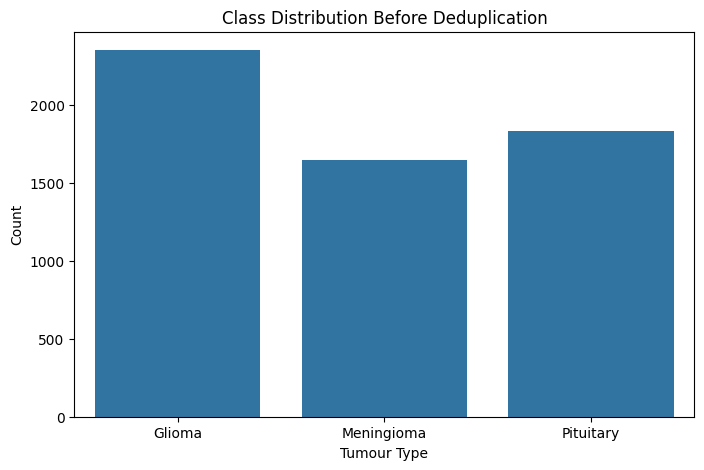

In [6]:
# Cell 4 — Collect image paths
def collect(paths, label):
    items = []
    for path in paths:
        for root, _, files in os.walk(path):
            for f in files:
                if f.lower().endswith(VALID_EXTENSIONS):
                    items.append((os.path.join(root, f), label))
    return items


data = (
    collect(GLIOMA_PATHS, 0)
    + collect(MENINGIOMA_PATHS, 1)
    + collect(PITUITARY_PATHS, 2)
)

df = pd.DataFrame(data, columns=["path", "label"])

print("Total Images before deduplication:", len(df))
print(df["label"].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(x=df["label"].map(CLASS_NAMES))
plt.title("Class Distribution Before Deduplication")
plt.xlabel("Tumour Type")
plt.ylabel("Count")
plt.show()

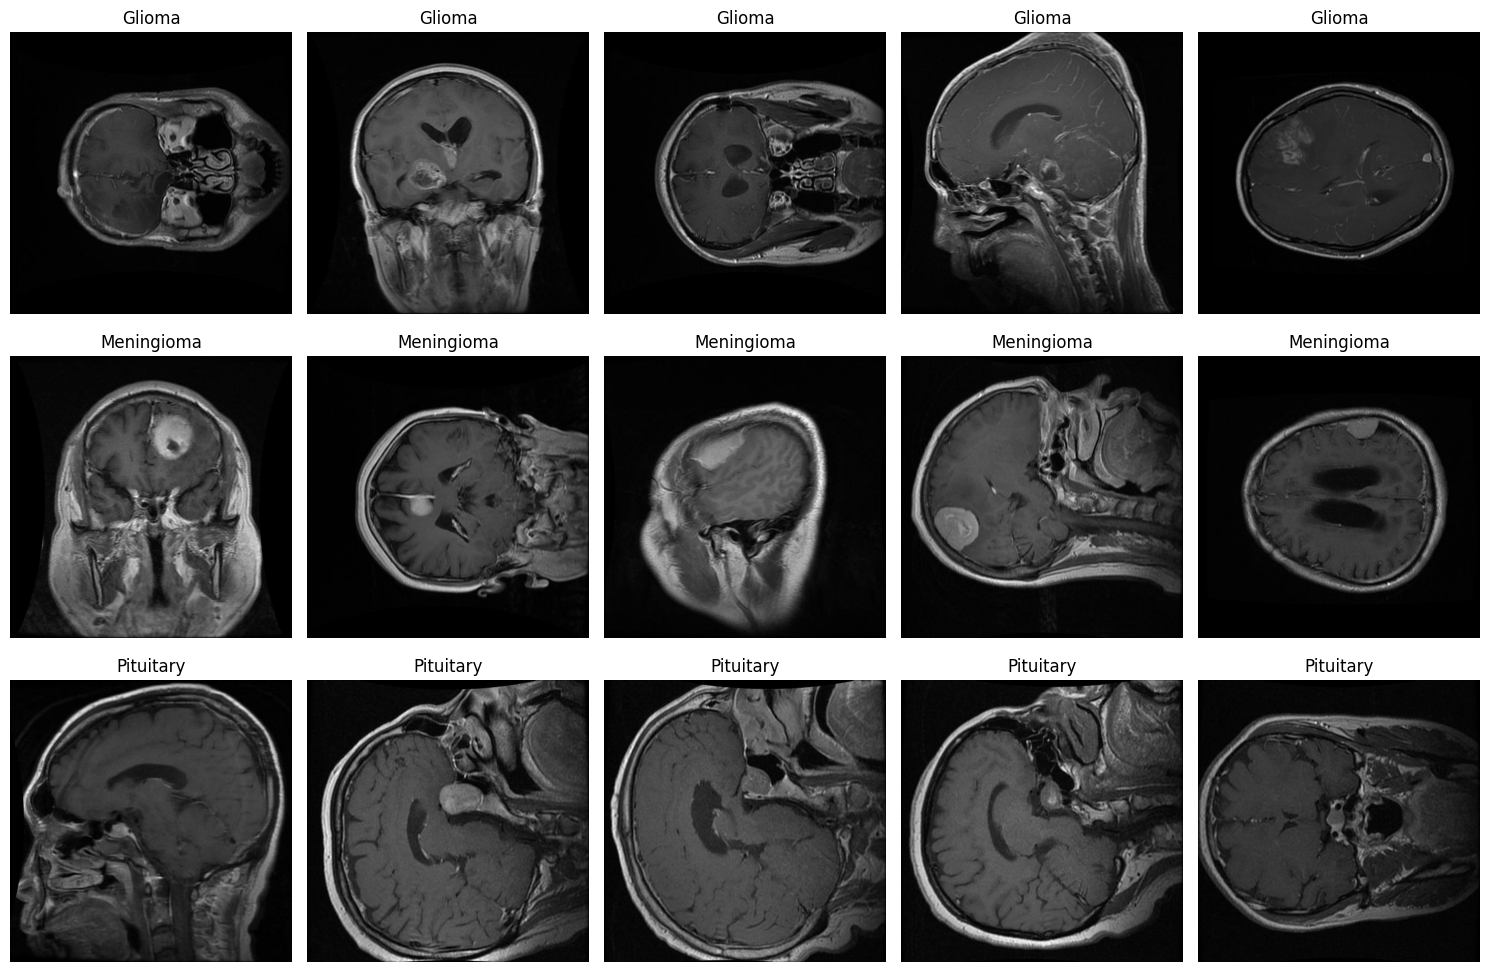

In [7]:
# Cell 5 — Sample images
fig, axes = plt.subplots(3, 5, figsize=(15, 10))

for label in CLASS_NAMES.keys():
    sample_paths = df[df["label"] == label]["path"].sample(5, random_state=SEED).values

    for idx, path in enumerate(sample_paths):
        img = Image.open(path).convert("RGB")
        axes[label, idx].imshow(img)
        axes[label, idx].set_title(CLASS_NAMES[label])
        axes[label, idx].axis("off")

plt.tight_layout()
plt.show()

Hashing images (pHash):   0%|          | 0/5828 [00:00<?, ?it/s]

Total Images after deduplication: 4705
label
0    2000
2    1401
1    1304
Name: count, dtype: int64


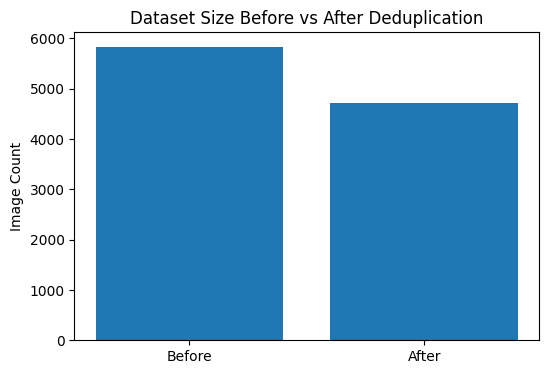

In [8]:
# Cell 6 — Perceptual-hash deduplication
import imagehash


def phash_image(path):
    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            return imagehash.phash(img)
    except Exception as e:
        print(f"Error reading {path}: {e}")
        return None


tqdm.pandas(desc="Hashing images (pHash)")
df["hash"] = df["path"].progress_apply(phash_image)

HAMMING_TOLERANCE = 5

unique_indices = []
seen_hashes = []

for idx, h in enumerate(df["hash"]):
    if h is None:
        continue
    if all(h - existing > HAMMING_TOLERANCE for existing in seen_hashes):
        seen_hashes.append(h)
        unique_indices.append(idx)

before_count = len(df)
df = df.loc[unique_indices].reset_index(drop=True)
df = df.drop(columns="hash")
after_count = len(df)

print("Total Images after deduplication:", after_count)
print(df["label"].value_counts())

plt.figure(figsize=(6, 4))
plt.bar(["Before", "After"], [before_count, after_count])
plt.title("Dataset Size Before vs After Deduplication")
plt.ylabel("Image Count")
plt.show()

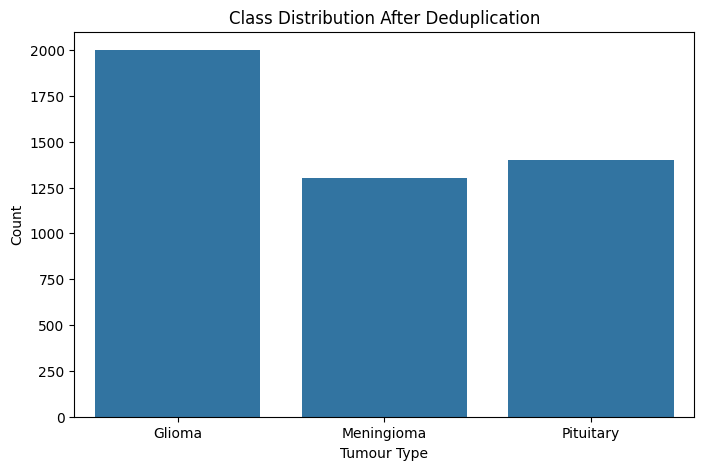

In [9]:
# Cell 7 — Class distribution after deduplication
plt.figure(figsize=(8, 5))
sns.countplot(x=df["label"].map(CLASS_NAMES))
plt.title("Class Distribution After Deduplication")
plt.xlabel("Tumour Type")
plt.ylabel("Count")
plt.show()

Train: 3293
Val:   706
Test:  706


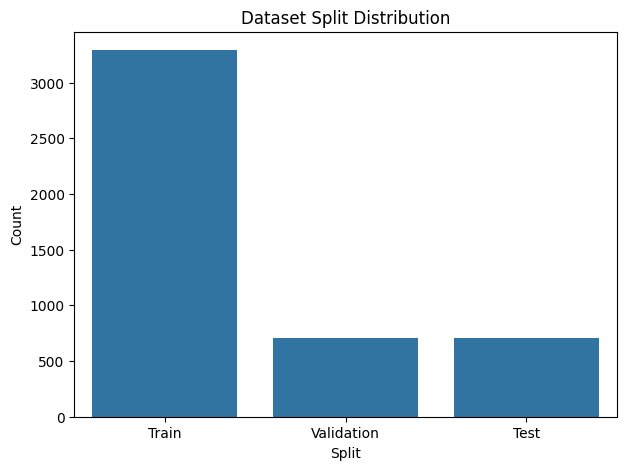

In [10]:
# Cell 8 — Train / val / test split (70 / 15 / 15)
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df["label"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=SEED,
)

print("Train:", len(train_df))
print("Val:  ", len(val_df))
print("Test: ", len(test_df))

split_df = pd.DataFrame(
    {
        "Split": ["Train", "Validation", "Test"],
        "Count": [len(train_df), len(val_df), len(test_df)],
    }
)

plt.figure(figsize=(7, 5))
sns.barplot(data=split_df, x="Split", y="Count")
plt.title("Dataset Split Distribution")
plt.show()

In [11]:
# Cell 9 — Dataset class
class BrainDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "path"]
        label = self.df.loc[idx, "label"]

        try:
            img = Image.open(img_path).convert("RGB")
        except Exception as e:
            raise RuntimeError(f"Failed loading image: {img_path}") from e

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.long)

In [12]:
# Cell 10 — Transforms
train_tfms = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(0.2, 0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

val_tfms = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

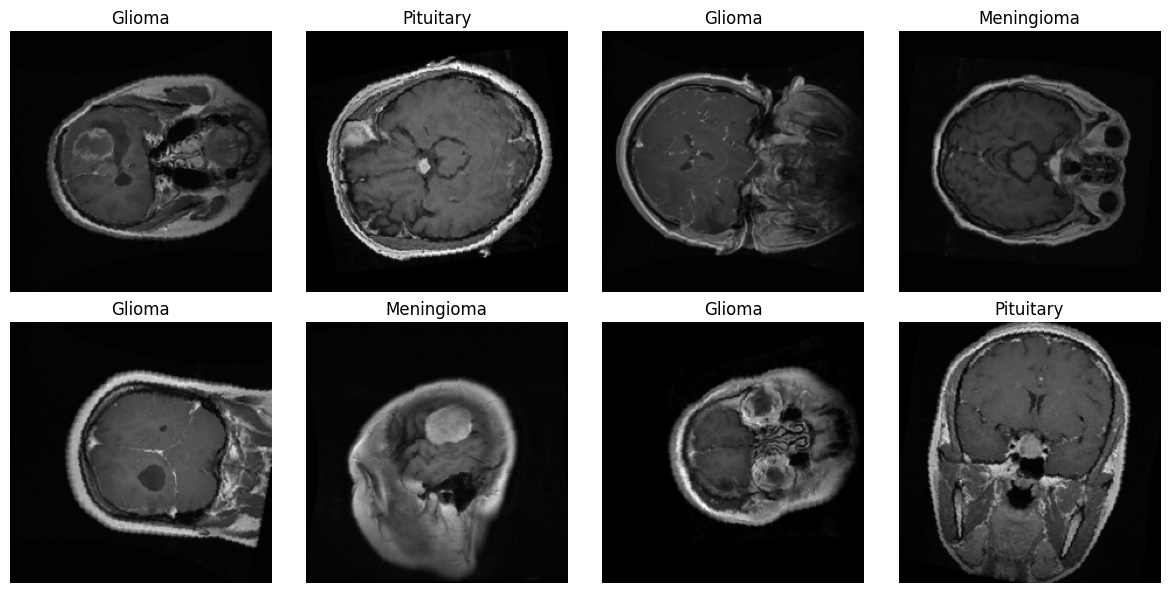

In [13]:
# Cell 11 — Augmented sample grid
sample_dataset = BrainDataset(train_df, train_tfms)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax in axes.flatten():
    image, label = sample_dataset[random.randint(0, len(sample_dataset) - 1)]
    image = image.permute(1, 2, 0).numpy()
    image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)
    ax.imshow(image)
    ax.set_title(CLASS_NAMES[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Cell 12 — DataLoaders
train_loader = DataLoader(
    BrainDataset(train_df, train_tfms),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=True,
)

val_loader = DataLoader(
    BrainDataset(val_df, val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=False,
)

test_loader = DataLoader(
    BrainDataset(test_df, val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=False,
)

In [15]:
# Cell 13 — Model, criterion, optimiser, scheduler
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 3)

if USE_MULTI_GPU:
    print("Using", torch.cuda.device_count(), "GPUs")
    model = nn.DataParallel(model)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

scaler = torch.amp.GradScaler("cuda")

print(model)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 139MB/s] 


Using 2 GPUs
DataParallel(
  (module): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
         

In [16]:
# Cell 14 — History dict
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_auc": [],
    "val_auc": [],
}

In [17]:
# Cell 15 — Epoch runner
# FIX: Always use autocast for both train and eval to keep dtype consistent
# with the DataParallel + TF32 configuration used during training.
def run_epoch(loader, training=True):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    ctx = torch.no_grad() if not training else torch.enable_grad()

    loop = tqdm(
        loader,
        total=len(loader),
        desc="Train" if training else "Val/Test",
        leave=False,
    )

    with ctx:
        for images, labels in loop:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            # FIX: autocast applied in both train and eval paths so tensor
            # dtypes are identical; avoids misaligned-address errors from
            # dtype/alignment mismatches under DataParallel.
            with torch.amp.autocast(device_type="cuda", enabled=True):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item()

            probs = torch.softmax(outputs.float(), dim=1).detach()
            all_preds.append(probs.cpu())
            all_labels.append(labels.detach().cpu())

            loop.set_postfix(loss=f"{loss.item():.4f}")

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds.argmax(axis=1))
    auc_score = roc_auc_score(
        np.eye(3)[all_labels.astype(int)],
        all_preds,
        multi_class="ovr",
    )

    return total_loss / len(loader), acc, auc_score

In [18]:
# Cell 16 — Training loop
log_dir = f"/kaggle/working/runs/{datetime.now().strftime('%Y%m%d-%H%M%S')}"
writer = SummaryWriter(log_dir)

best_auc = 0.0

for epoch in range(EPOCHS):
    print(f"\n===== Epoch {epoch + 1}/{EPOCHS} =====")

    train_loss, train_acc, train_auc = run_epoch(train_loader, True)
    val_loss, val_acc, val_auc = run_epoch(val_loader, False)

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_auc"].append(train_auc)
    history["val_auc"].append(val_auc)

    print(
        f"Train | Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | AUC: {train_auc:.4f}"
    )
    print(f"Val   | Loss: {val_loss:.4f} | Acc: {val_acc:.4f} | AUC: {val_auc:.4f}")

    writer.add_scalar("Loss/Train", train_loss, epoch)
    writer.add_scalar("Loss/Val", val_loss, epoch)
    writer.add_scalar("AUC/Train", train_auc, epoch)
    writer.add_scalar("AUC/Val", val_auc, epoch)

    if val_auc > best_auc:
        best_auc = val_auc
        # FIX: always save the unwrapped (non-DataParallel) state_dict so the
        # checkpoint can be loaded on any number of GPUs without key-name
        # mismatches (DataParallel prefixes every key with "module.").
        state_dict = model.module.state_dict() if USE_MULTI_GPU else model.state_dict()
        torch.save(state_dict, "/kaggle/working/best_efficientnet_b0_multi_class.pth")
        print("Best model saved.")

writer.close()


===== Epoch 1/10 =====


Train:   0%|          | 0/12 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/3 [00:00<?, ?it/s]

Train | Loss: 0.6543 | Acc: 0.7451 | AUC: 0.9034
Val   | Loss: 0.7204 | Acc: 0.7280 | AUC: 0.9442
Best model saved.

===== Epoch 2/10 =====


Train:   0%|          | 0/12 [00:00<?, ?it/s]

...

Val/Test:   0%|          | 0/3 [00:00<?, ?it/s]

Train | Loss: 0.0470 | Acc: 0.9831 | AUC: 0.9994
Val   | Loss: 0.1313 | Acc: 0.9547 | AUC: 0.9954

===== Epoch 10/10 =====


Train:   0%|          | 0/12 [00:00<?, ?it/s]

Val/Test:   0%|          | 0/3 [00:00<?, ?it/s]

Train | Loss: 0.0475 | Acc: 0.9831 | AUC: 0.9994
Val   | Loss: 0.1327 | Acc: 0.9547 | AUC: 0.9952


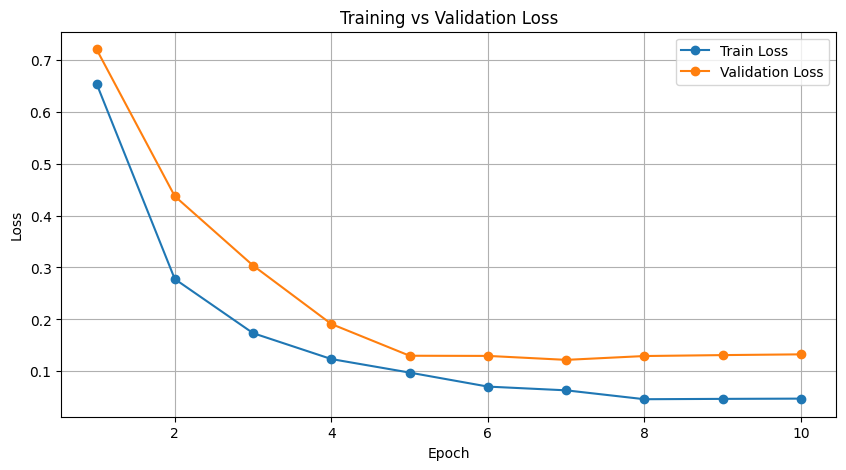

In [19]:
# Cell 17 — Loss curves
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

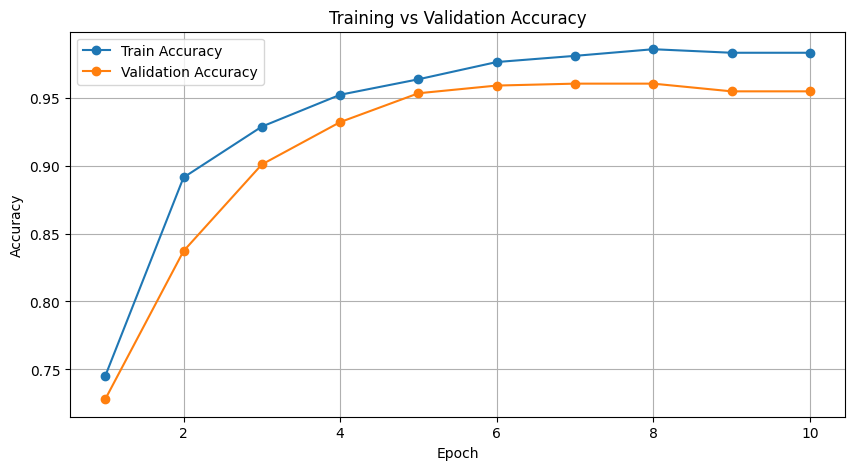

In [20]:
# Cell 18 — Accuracy curves
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

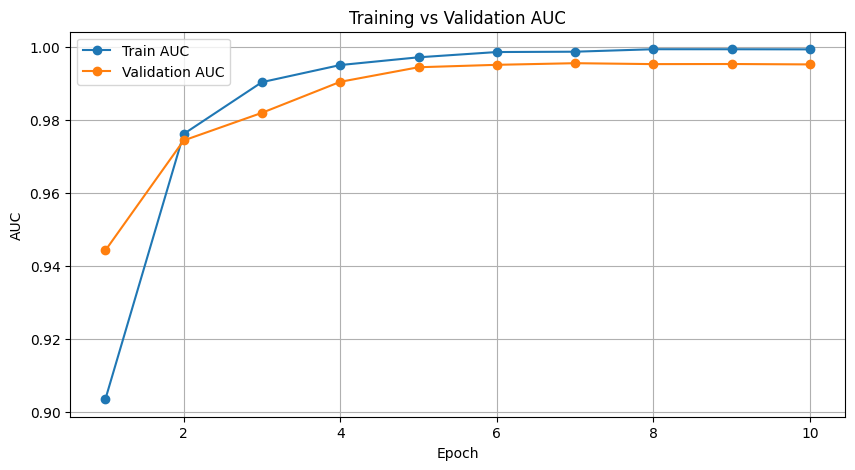

In [21]:
# Cell 19 — AUC curves
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, history["train_auc"], marker="o", label="Train AUC")
plt.plot(epochs_range, history["val_auc"], marker="o", label="Validation AUC")
plt.title("Training vs Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
# Cell 20 — Load best checkpoint and run test evaluation
# FIX: Rebuild a plain (non-DataParallel) model for inference.
# The checkpoint was saved from model.module, so it loads cleanly here.
# This completely avoids the DataParallel CUDA misaligned-address crash.
inference_model = efficientnet_b0(weights=None)
inference_model.classifier[1] = nn.Linear(inference_model.classifier[1].in_features, 3)
state_dict = torch.load(
    "/kaggle/working/best_efficientnet_b0_multi_class.pth",
    map_location=DEVICE,
)
inference_model.load_state_dict(state_dict)
inference_model = inference_model.to(DEVICE)
inference_model.eval()

# Temporarily swap model reference so run_epoch uses the plain model
_train_model = model
model = inference_model

test_loss, test_acc, test_auc = run_epoch(test_loader, training=False)

print("\n===== FINAL UNSEEN TEST RESULTS =====")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test AUC:      {test_auc:.4f}")

# Restore original model reference
model = _train_model

Val/Test:   0%|          | 0/3 [00:00<?, ?it/s]


===== FINAL UNSEEN TEST RESULTS =====
Test Loss:     0.0557
Test Accuracy: 0.9844
Test AUC:      0.9988


In [23]:
# Cell 21 — Collect all test probabilities and targets for detailed metrics
# FIX: Use inference_model (plain EfficientNet, no DataParallel) with
# autocast + no_grad. This is the cell that crashed originally due to the
# DataParallel misaligned-address error.
all_probs = []
all_targets = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Collecting predictions"):
        images = images.to(DEVICE)

        with torch.amp.autocast(device_type="cuda", enabled=True):
            outputs = inference_model(images)

        # Cast to float32 before softmax to avoid half-precision edge cases
        probs = torch.softmax(outputs.float(), dim=1)

        all_probs.append(probs.cpu())
        all_targets.append(labels)

all_probs = torch.cat(all_probs).numpy()
all_targets = torch.cat(all_targets).numpy()
predictions = np.argmax(all_probs, axis=1)

print(f"Collected {len(all_targets)} test samples.")

Collected 706 test samples.


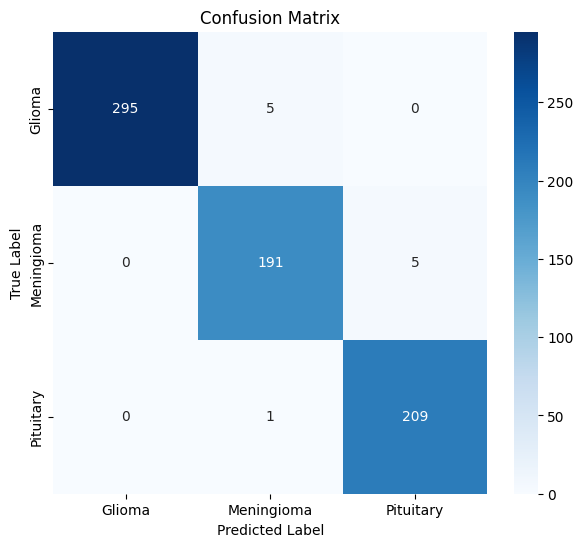

In [24]:
# Cell 22 — Confusion matrix
cm = confusion_matrix(all_targets, predictions)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES.values(),
    yticklabels=CLASS_NAMES.values(),
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [25]:
# Cell 23 — Classification report
print(
    classification_report(
        all_targets,
        predictions,
        target_names=list(CLASS_NAMES.values()),
    )
)

              precision    recall  f1-score   support

      Glioma       1.00      0.98      0.99       300
  Meningioma       0.97      0.97      0.97       196
   Pituitary       0.98      1.00      0.99       210

    accuracy                           0.98       706
   macro avg       0.98      0.98      0.98       706
weighted avg       0.98      0.98      0.98       706



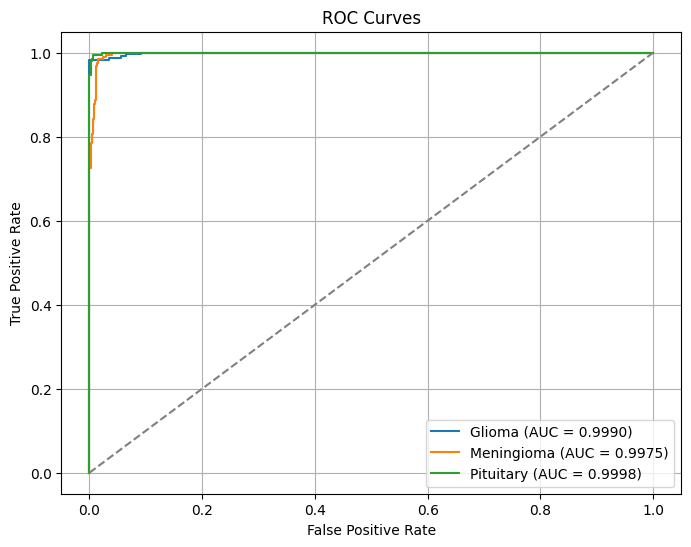

In [26]:
# Cell 24 — Per-class ROC curves
plt.figure(figsize=(8, 6))

for idx, class_name in CLASS_NAMES.items():
    fpr, tpr, _ = roc_curve(
        (all_targets == idx).astype(int),
        all_probs[:, idx],
    )
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

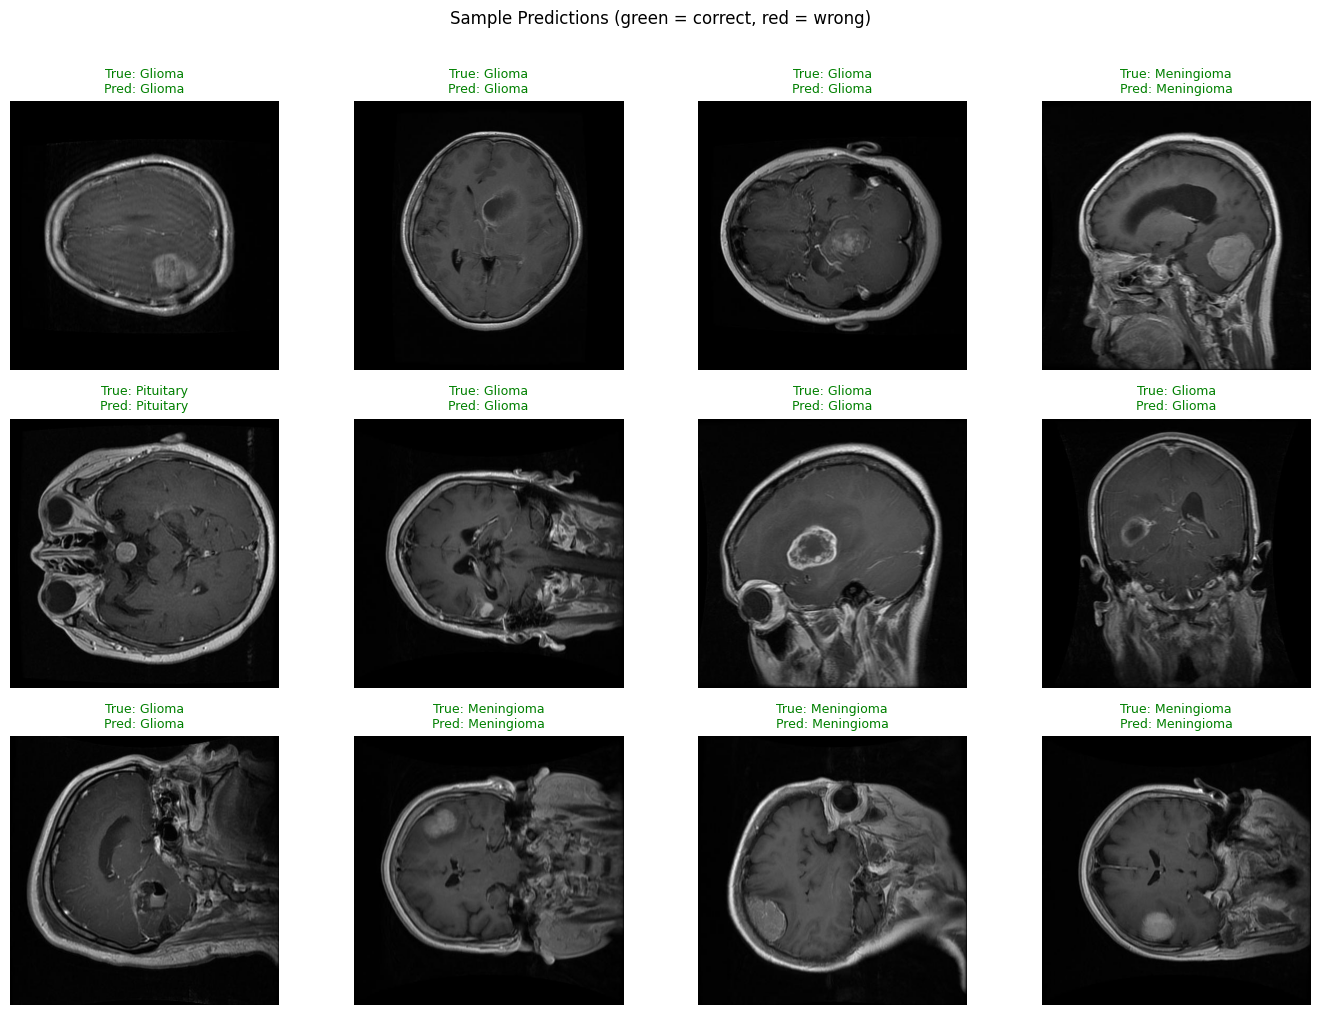

In [27]:
# Cell 25 — Visual prediction grid
# FIX: Use inference_model with autocast + no_grad (no DataParallel).
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

sample_indices = np.random.choice(
    range(len(test_df)),
    size=12,
    replace=False,
)

for ax, idx in zip(axes.flatten(), sample_indices):
    img_path = test_df.iloc[idx]["path"]
    true_label = test_df.iloc[idx]["label"]

    image = Image.open(img_path).convert("RGB")
    tensor_img = val_tfms(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        with torch.amp.autocast(device_type="cuda", enabled=True):
            output = inference_model(tensor_img)
        pred = torch.argmax(output, dim=1).item()

    color = "green" if pred == true_label else "red"
    ax.imshow(image)
    ax.set_title(
        f"True: {CLASS_NAMES[true_label]}\nPred: {CLASS_NAMES[pred]}",
        color=color,
        fontsize=9,
    )
    ax.axis("off")

plt.suptitle("Sample Predictions (green = correct, red = wrong)", y=1.01)
plt.tight_layout()
plt.show()

In [28]:
# Cell 26 — Save final model
# FIX: Save inference_model state_dict (already unwrapped from DataParallel).
torch.save(
    inference_model.state_dict(),
    "/kaggle/working/final_efficientnet_b0_brain_tumor_multi_class.pth",
)
print("Final model saved.")

Final model saved.
